<a href="https://colab.research.google.com/github/sh410766/Estad-stica-1/blob/main/Tarea2_Estadistica_I_(2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tarea 2 · Estadística descriptiva en Python

**Universidad Industrial de Santander · Escuela de Matemáticas · Estadística I**  
**Profesor:** Andrés Ríos-Gutiérrez  
**Estudiantes:**  
- Freddy Santiago Hernandez Gelves (2240643)  
- Ashly Michelle Peña Sanchez (2241195)

## Introducción

En este cuaderno describimos, con las herramientas de la estadística descriptiva vistas en clase, dos variables de los **nacimientos registrados en Colombia durante 2024**: la **edad del padre** (`EDAD_PADRE`) y el **número de embarazos de la madre, contando el actual** (`N_EMB`). También estudiamos si las dos variables están relacionadas. Con esto respondemos tres preguntas:

1. ¿Cómo se comporta `EDAD_PADRE`?
2. ¿Cómo se comporta `N_EMB`?
3. ¿Están correlacionadas y con qué grado?

El cuaderno sigue este orden: (1) carga y descripción de la base; (2) limpieza de datos con su justificación; (3) y (4) análisis univariado de cada variable, con gráficos y medidas de posición, tendencia central, dispersión y forma; (5) prueba de normalidad de Shapiro-Wilk; (6) análisis bivariado con diagrama de dispersión y los coeficientes de Pearson, Spearman y Kendall; y (7) conclusiones. Cada resultado va acompañado de su interpretación, y el código completo está en las celdas del cuaderno y en el anexo final.

## Origen de los datos

Las **Estadísticas Vitales (EEVV)** del DANE se construyen a partir de los **certificados de nacido vivo**, que diligencia el personal de salud en el momento del nacimiento (o, si no es posible, la autoridad competente). Cada fila de la base es **un nacido vivo**, y las columnas recogen datos del bebé, de la madre, del padre y de la atención del parto. Es un **registro administrativo de cobertura nacional**: no es una muestra sino el conjunto de nacimientos reportados, así que no hay error de muestreo, pero sí puede haber errores de diligenciamiento y campos sin información.

Fuente: [DANE, Microdatos, catálogo 878](https://microdatos.dane.gov.co/index.php/catalog/878).

## 1. Carga de la base de datos

In [1]:
import io, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats

warnings.filterwarnings('ignore', category=FutureWarning)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 300, 'axes.titleweight': 'bold'})

**Interpretación.** Importamos `numpy` y `pandas` para manejar los datos, `matplotlib` y `seaborn` para los gráficos, `scipy.stats` para las pruebas estadísticas, la media geométrica, la densidad normal y los coeficientes de correlación, y `statsmodels` para el gráfico Q-Q. También silenciamos las advertencias de versiones futuras de SciPy y fijamos 300 dpi como resolución al guardar las figuras.

In [2]:

try:
    from google.colab import files
    uploaded = files.upload()
    nombre_archivo = list(uploaded.keys())[0]
    io_csv = io.BytesIO(uploaded[nombre_archivo])
    # Si es un archivo zip, se indica la compresión
    compresion = 'zip' if nombre_archivo.endswith('.zip') else None
except ImportError:
    io_csv = 'BD-EEVV-Nacimientos-2024.csv'
    compresion = None

tabla = pd.read_csv(io_csv, sep=",", index_col=0, encoding='latin-1', compression=compresion)
tabla.head(3)

Saving BD-EEVV-Nacimientos-2024 (2).zip to BD-EEVV-Nacimientos-2024 (2).zip


,COD_MUNIC,AREANAC,SIT_PARTO,OTRO_SIT,SEXO,PESO_NAC,TALLA_NAC,ANO,MES,ATEN_PAR,...,N_HIJOSV,FECHA_NACM,N_EMB,SEG_SOCIAL,IDCLASADMI,EDAD_PADRE,NIV_EDUP,ULTCURPAD,PROFESION,TIPOFORMULARIO
COD_DPTO,,,,,,,,,,,,,,,,,,,,,
76,1,1,1,NaN,2,6,5,2024,5,1,...,2,21/09/2017,2,2,2.0,39,4,11,1.0,1
19,473,3,2,NaN,1,7,4,2024,6,5,...,3,27/06/2023,3,2,2.0,27,3,9,1.0,1
41,298,1,1,NaN,1,6,5,2024,4,1,...,3,23/06/2020,3,2,2.0,28,4,11,1.0,1


**Qué hace cada línea.**
- `files.upload()` abre el selector de archivos de Colab y devuelve un diccionario `{nombre: contenido en bytes}`. Con `io.BytesIO` convertimos esos bytes en un objeto parecido a un archivo, que `pandas` sí puede leer. Si el archivo subido es un `.zip`, `compression='zip'` le indica a `pandas` que lo lea directamente (el ZIP debe contener un solo CSV); con un `.csv` no se usa compresión. El `try/except` solo existe para poder correr el cuaderno también fuera de Colab, leyendo el CSV desde la carpeta local.
- `sep=","` indica que las columnas están separadas por comas. `index_col=0` toma la primera columna (el código del departamento) como índice de las filas; ese índice se repite, porque hay muchos nacimientos por departamento, así que no identifica a cada fila. `encoding='latin-1'` es necesario porque el archivo no está en UTF-8, y así se leen bien las tildes y la ñ.
- `tabla.head(3)` muestra las tres primeras filas para comprobar que la lectura salió bien.

In [3]:
print("Dimensiones (filas, columnas):", tabla.shape)
print("Año de los registros:", tabla['ANO'].unique())
tabla[['EDAD_PADRE', 'N_EMB']].dtypes

Dimensiones (filas, columnas): (453901, 39)
Año de los registros: [2024]


,0
EDAD_PADRE,int64
N_EMB,int64


**Interpretación.** La base tiene **453.901 nacimientos** y **39 variables**, todos del año 2024. Las dos variables que nos interesan son numéricas enteras: `EDAD_PADRE` está en años cumplidos y `N_EMB` es un conteo que incluye el embarazo actual, por lo que su mínimo posible es 1. `pandas` no reporta valores faltantes (`NaN`) en ellas, pero eso no significa que estén completas, como se ve a continuación.

## 2. Limpieza de datos

In [4]:
df = tabla[['EDAD_PADRE', 'N_EMB']].copy()
print("Valores NaN por columna:\n", df.isna().sum(), "\n")
print(df.describe().round(2))
print("\nEDAD_PADRE == 999:", (df['EDAD_PADRE'] == 999).sum())
print("N_EMB == 99      :", (df['N_EMB'] == 99).sum())

Valores NaN por columna:
 EDAD_PADRE    0
N_EMB         0
dtype: int64 

       EDAD_PADRE      N_EMB
count   453901.00  453901.00
mean        51.92       3.89
std        142.98      13.32
min         12.00       1.00
25%         25.00       1.00
50%         30.00       2.00
75%         35.00       3.00
max        999.00      99.00

EDAD_PADRE == 999: 10086
N_EMB == 99      : 8649


**Interpretación.** Aunque no hay `NaN`, el máximo de `EDAD_PADRE` es **999** y el de `N_EMB` es **99**, valores imposibles como edad o como número de embarazos. En las estadísticas vitales del DANE son códigos de “sin información”, que se usan cuando el certificado no registra el dato (así aparecen en el diccionario de variables del catálogo 878). Si no los tratáramos, la media de `EDAD_PADRE` se inflaría de unos 30 a unos 52 años y su desviación estándar saltaría a casi 143.

In [5]:
# ¿Dónde faltan los datos? Se cruza con el estado civil de la madre (9 = sin información)
base = tabla[['EDAD_PADRE', 'N_EMB', 'N_HIJOSV', 'EST_CIVM', 'MUL_PARTO', 'EDAD_MADRE']].reset_index(drop=True)
falta_padre = base['EDAD_PADRE'] == 999
sin_estado  = base['EST_CIVM'] == 9

print(f"Edad del padre sin información: {falta_padre.sum():,}")
print(f"  de ellos, con estado civil de la madre también sin información: {(falta_padre & sin_estado).sum():,} "
      f"({(falta_padre & sin_estado).sum() / falta_padre.sum() * 100:.1f} %)")
print(f"Certificados con estado civil sin información: {sin_estado.sum():,}; "
      f"{falta_padre[sin_estado].mean() * 100:.1f} % de ellos no trae la edad del padre")
print(f"Resto de certificados: {falta_padre[~sin_estado].mean() * 100:.2f} % no trae la edad del padre")
print(f"\nN_EMB sin información: {(base['N_EMB'] == 99).sum():,}; "
      f"de ellos, también sin N_HIJOSV: {((base['N_EMB'] == 99) & (base['N_HIJOSV'] == 99)).sum():,}")

# Coherencia: una madre no puede tener más hijos nacidos vivos (incluido el actual) que embarazos,
# salvo en partos múltiples (MUL_PARTO: 1 = simple, 2 = doble, 3 = triple, 4 = cuádruple o más)
valido = base[(base['N_EMB'] != 99) & (base['N_HIJOSV'] != 99)]
inc = valido[valido['N_EMB'] < valido['N_HIJOSV']]
multiples = inc['MUL_PARTO'].isin([2, 3, 4]).sum()
simples = (inc['MUL_PARTO'] == 1).sum()
print(f"\nRegistros con N_EMB < N_HIJOSV: {len(inc):,} ({len(inc) / len(valido) * 100:.2f} % de los válidos)")
print(f"  partos múltiples: {multiples:,} ({multiples / len(inc) * 100:.1f} %)")
print(f"  partos simples:   {simples:,} ({simples / len(valido) * 100:.2f} % de los válidos)")

Edad del padre sin información: 10,086
  de ellos, con estado civil de la madre también sin información: 8,902 (88.3 %)
Certificados con estado civil sin información: 16,746; 53.2 % de ellos no trae la edad del padre
Resto de certificados: 0.27 % no trae la edad del padre

N_EMB sin información: 8,649; de ellos, también sin N_HIJOSV: 8,611

Registros con N_EMB < N_HIJOSV: 5,396 (1.21 % de los válidos)
  partos múltiples: 3,889 (72.1 %)
  partos simples:   1,507 (0.34 % de los válidos)


**Interpretación.**
- **Dónde faltan los datos.** El 88,3 % de los certificados sin edad del padre tampoco tiene el estado civil de la madre. Entre los certificados con estado civil sin información, más de la mitad (53,2 %) no trae la edad del padre, mientras que en el resto la proporción es de apenas 0,27 %. Algo parecido pasa con el historial de la madre: casi todos los `N_EMB` sin información (8.611 de 8.649) coinciden con `N_HIJOSV` sin información. Los faltantes, entonces, no se reparten al azar: se concentran en formularios que quedaron incompletos.
- **Coherencia entre variables.** Una madre no puede tener más hijos nacidos vivos (contando el actual) que embarazos, salvo en partos múltiples. Esto ocurre en 1,21 % de los registros válidos y el 72,1 % de esos casos son partos múltiples, lo que los explica. Quedan 1.507 partos simples (0,34 %) con esa inconsistencia, un error de diligenciamiento pequeño que no podemos corregir con esta base.

In [6]:
n_inicial = len(df)
df = df.replace({'EDAD_PADRE': {999: np.nan}, 'N_EMB': {99: np.nan}})   # cada código en su columna
print("Faltantes tras recodificar:\n", df.isna().sum())
print(f"\nRegistros con al menos un dato faltante: {df.isna().any(axis=1).sum()} "
      f"({df.isna().any(axis=1).mean()*100:.2f} %)")

df = df.dropna().astype(int)       # eliminación por casos completos (listwise)
print(f"Registros iniciales: {n_inicial:,} -> finales: {len(df):,}")

Faltantes tras recodificar:
 EDAD_PADRE    10086
N_EMB          8649
dtype: int64

Registros con al menos un dato faltante: 10124 (2.23 %)
Registros iniciales: 453,901 -> finales: 443,777


**Decisiones y justificación.**
- **Recodificación.** Pasamos 999 y 99 a `NaN`, porque no son mediciones sino marcas de dato ausente.
- **Eliminación por casos completos.** La correlación necesita pares completos y la pérdida es pequeña: 10.124 registros (2,23 %). En la literatura sobre datos faltantes se acepta que una pérdida de 5 % o menos tiene consecuencias mínimas (Schafer, 1999, citado en Dong y Peng, 2013), aunque esa regla supone que los datos faltan más o menos al azar, y ese es justamente el punto débil de nuestro caso (véase la limitación). Imputar con la media sería peor, pues reduciría artificialmente la varianza y debilitaría la correlación (Little y Rubin, 2019). Antes de eliminar, además, identificamos los códigos 999 y 99 como valores faltantes, tal como Schafer y Graham (2002) recomiendan hacer con los códigos de “no respuesta”. Quedan **443.777 registros**.
- **Limitación.** Según el cruce anterior, la ausencia de datos no es del todo aleatoria, porque se concentra en certificados mal diligenciados. Con una pérdida de solo 2,2 % esperamos un sesgo pequeño, pero no podemos descartarlo.

In [7]:
print("EDAD_PADRE < 15 años :", (df['EDAD_PADRE'] < 15).sum())
print("EDAD_PADRE >= 70 años:", (df['EDAD_PADRE'] >= 70).sum())
print("N_EMB >= 10          :", (df['N_EMB'] >= 10).sum())

EDAD_PADRE < 15 años : 168
EDAD_PADRE >= 70 años: 95
N_EMB >= 10          : 616


In [8]:
# Padres muy jóvenes: ¿qué edad tiene la madre en esos registros? (EDAD_MADRE: 1 = 10-14, 2 = 15-19, 3 = 20-24, ...)
jov = base[base['EDAD_PADRE'] < 15]
print(f"Padres de menos de 15 años: {len(jov)}")
print(f"  con madre de 19 años o menos: {(jov['EDAD_MADRE'] <= 2).sum()}")
print(f"  con madre de 20 años o más:   {jov['EDAD_MADRE'].between(3, 9).sum()}")

Padres de menos de 15 años: 168
  con madre de 19 años o menos: 159
  con madre de 20 años o más:   9


**Decisión sobre los valores extremos.** Hay 168 padres menores de 15 años, 95 de 70 años o más y 616 madres con 10 o más embarazos. Son valores poco frecuentes pero posibles, no errores evidentes, así que los conservamos. En los padres menores de 15 años, 159 de los 168 tienen pareja de 19 años o menos, lo que vuelve creíble el dato; solo 9 tienen madre de 20 años o más y podrían ser errores de digitación, pero son demasiado pocos para influir en los resultados. Más adelante los identificamos formalmente como datos atípicos (sección 3.5) y comprobamos que no condicionan la correlación (sección 6).

## Funciones auxiliares

Definimos una sola vez las funciones que implementan las medidas vistas en clase, para aplicarlas después a cada variable.

In [9]:
def cuantiles(x, ps):
    # Cuantiles con la fórmula de clase: posición = p(n+1) sobre los datos ordenados y
    # Cuantil = L_p + (L_{p+1} - L_p) * parte decimal de la posición.
    xs = np.sort(np.asarray(x, dtype=float)); n = len(xs); salida = []
    for p in ps:
        pos = p * (n + 1)
        if pos <= 1:   salida.append(xs[0]);  continue
        if pos >= n:   salida.append(xs[-1]); continue
        k = int(pos)
        salida.append(xs[k - 1] + (xs[k] - xs[k - 1]) * (pos - k))
    return np.array(salida)

def tabla_posicion(x):
    grupos = {'Cuartiles':    {'Q1': .25, 'Q2 (mediana)': .50, 'Q3': .75},
              'Quintiles':    {'K1': .20, 'K2': .40, 'K3': .60, 'K4': .80},
              'Deciles':      {f'D{i}': i / 10 for i in range(1, 10)},
              'Percentiles':  {'P1': .01, 'P5': .05, 'P95': .95, 'P99': .99}}
    filas = []
    for tipo, d in grupos.items():
        for (nombre, p), v in zip(d.items(), cuantiles(x, list(d.values()))):
            filas.append((tipo, nombre, f'{p*100:g} %', v))
    return pd.DataFrame(filas, columns=['Tipo', 'Medida', 'Posición', 'Valor']).set_index(['Tipo', 'Medida'])

def tabla_central(x):
    x = np.asarray(x, float); moda = pd.Series(x).mode()
    return pd.Series({'Media aritmética': x.mean(), 'Media geométrica': stats.gmean(x),
                      'Mediana': np.median(x), 'Moda': moda.iloc[0], 'N.º de modas': len(moda)})

def tabla_dispersion(x):
    x = np.asarray(x, float); m = x.mean(); q1, q3 = cuantiles(x, [.25, .75])
    return pd.Series({'Rango': np.ptp(x), 'RIC (Q3 - Q1)': q3 - q1,
                      'Desviación media (Dm)': np.mean(np.abs(x - m)),
                      'Varianza poblacional': x.var(ddof=0), 'Varianza muestral (S²)': x.var(ddof=1),
                      'Desv. estándar poblacional': x.std(ddof=0), 'Desv. estándar muestral (S)': x.std(ddof=1)})

def tabla_cv(x):
    # CV respecto a cada medida de tendencia central: raíz de la distancia cuadrada media a la medida / medida
    x = np.asarray(x, float)
    mtc = {'Media': x.mean(), 'Mediana': np.median(x), 'Moda': pd.Series(x).mode().iloc[0], 'Media geométrica': stats.gmean(x)}
    return pd.Series({f'CV respecto a la {k.lower()} (%)': np.sqrt(np.mean((x - v) ** 2)) / v * 100 for k, v in mtc.items()})

def tabla_forma(x):
    x = np.asarray(x, float); m = x.mean(); sd = x.std(ddof=0)
    mu3, mu4 = np.mean((x - m) ** 3), np.mean((x - m) ** 4)
    q1, med, q3, p10, p90 = cuantiles(x, [.25, .5, .75, .10, .90])
    moda = pd.Series(x).mode().iloc[0]
    return pd.Series({'Momento central 3 (μ3)': mu3, 'Momento central 4 (μ4)': mu4,
                      'Asimetría de Fisher (μ3/S³)': mu3 / sd ** 3,
                      'Asimetría de Bowley-Yule': (q3 + q1 - 2 * med) / (q3 - q1),
                      'Asimetría de Pearson ((media-moda)/S)': (m - moda) / x.std(ddof=1),
                      'Curtosis respecto a la media (μ4/S⁴)': mu4 / sd ** 4,
                      'Curtosis respecto a la mediana ((Q3-Q1)/(P90-P10))': (q3 - q1) / (p90 - p10)})

def atipicos(x):
    x = np.asarray(x, float); z = (x - x.mean()) / x.std(ddof=1)
    lo, hi = cuantiles(x, [.0015, .9985])
    fuera = (x < lo) | (x > hi)
    return pd.Series({'Intervalo confiable por z: límite inferior': x.mean() - 3 * x.std(ddof=1),
                      'Intervalo confiable por z: límite superior': x.mean() + 3 * x.std(ddof=1),
                      'Atípicos por z (|z| > 3)': int((np.abs(z) > 3).sum()),
                      '   % del total': (np.abs(z) > 3).mean() * 100,
                      'Intervalo por cuantiles: límite inferior (Cuantil 0,15 %)': lo,
                      'Intervalo por cuantiles: límite superior (Cuantil 99,85 %)': hi,
                      'Atípicos por cuantiles': int(fuera.sum()),
                      '   % del total ': fuera.mean() * 100,
                      '   por debajo': int((x < lo).sum()), '   por encima': int((x > hi).sum())})

def fig_distribucion(x, nombre, bins, archivo, factor=None):
    x = np.asarray(x, float); m, S = x.mean(), x.std(ddof=1)
    kde = stats.gaussian_kde(x, bw_method=factor); g = np.linspace(x.min() - 2, x.max() + 2, 400); dens = kde(g)
    bw = kde.factor * S
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
    ax[0].hist(x, bins=bins, density=True, color='#F28E2B', edgecolor='k', alpha=.85, label='Histograma')
    ax[0].plot(g, dens, color='red', lw=2, label='Densidad (método Kernel)')
    ax[0].plot(g, stats.norm.pdf(g, m, S), color='k', lw=2, label=f'Normal (μ={m:.2f}, S={S:.2f})')
    ax[0].set(title='Histograma, densidad Kernel y normal', xlabel=nombre, ylabel='Densidad'); ax[0].legend(fontsize=8)
    ax[1].plot(g, dens, color='blue', lw=2); ax[1].axhline(0, color='lightgray')
    ax[1].set(title='Función de densidad estimada', xlabel=f'{nombre}\nN = {len(x):,}   Ancho de banda = {bw:.4f}', ylabel='Densidad')
    sm.qqplot(pd.Series(x).sample(20000, random_state=1).values, line='q', ax=ax[2], markersize=3, alpha=.4)
    ax[2].set_title('Q-Q plot respecto a la normal')
    plt.tight_layout(); plt.savefig(archivo); plt.show()
    return bw

def tallos_hojas(v):
    v = np.sort(np.asarray(v, int))
    for t in range(v.min() // 10, v.max() // 10 + 1):
        print(f'{t:>2} | ' + ''.join(str(h) for h in v[v // 10 == t] % 10))

**Interpretación.** Cada función corresponde a un tema de la clase:
- `cuantiles` usa la fórmula de posición $p(n+1)$ sobre los datos ordenados, con interpolación lineal entre los dos datos vecinos. Equivale al método `'weibull'` de `numpy`, lo que verificamos más adelante.
- `tabla_posicion`, `tabla_central`, `tabla_dispersion`, `tabla_cv` y `tabla_forma` calculan las medidas de posición, de tendencia central (media, geométrica, mediana y moda), de dispersión (desviación media, varianzas, desviaciones estándar y coeficientes de variación) y de forma (asimetría y curtosis).
- `atipicos` aplica los dos criterios vistos en clase: la estandarización ($|z|>3$) y, cuando no hay normalidad, el intervalo entre los cuantiles 0,15 % y 99,85 %.
- `fig_distribucion` dibuja el histograma con la densidad Kernel y la normal, la función de densidad estimada y el Q-Q plot. El ancho de banda del Kernel es automático por defecto, y el parámetro `factor` permite fijarlo.
- `tallos_hojas` construye el diagrama de tallos y hojas (tallo = decena, hoja = unidad).

## 3. Pregunta 1: comportamiento de `EDAD_PADRE`

### 3.1 Gráficos estadísticos

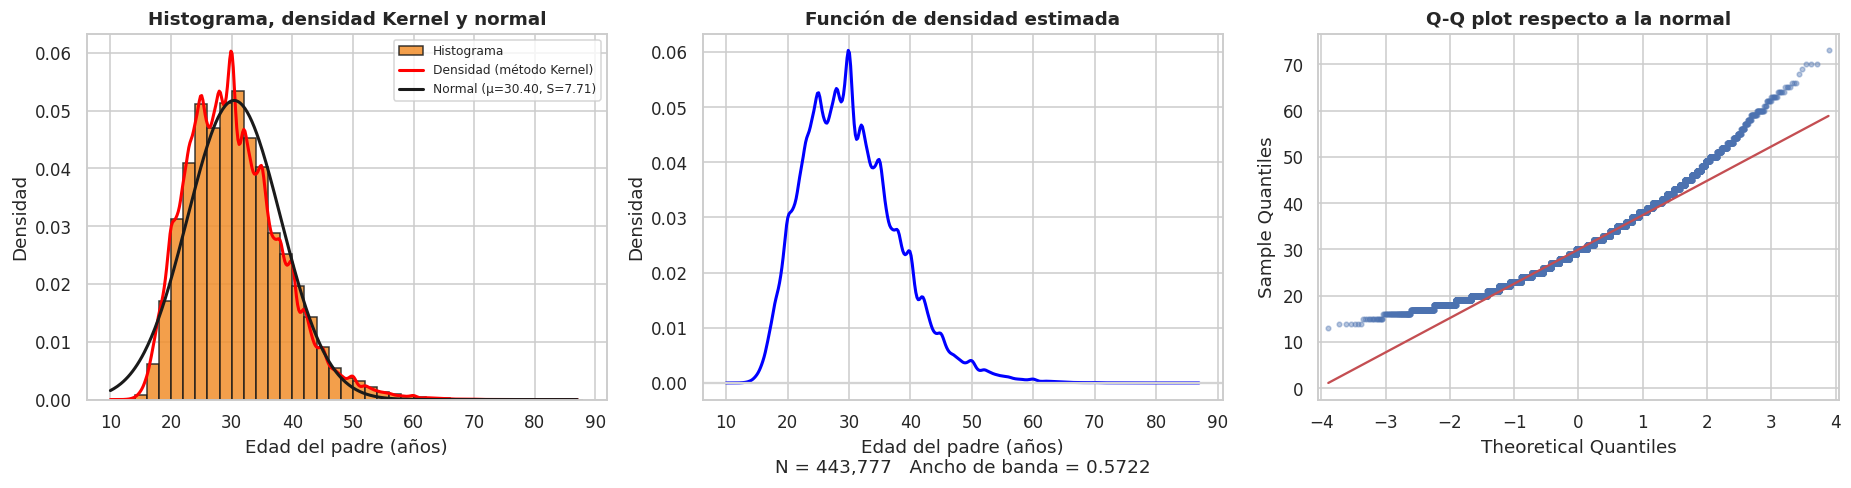

In [10]:
x = df['EDAD_PADRE']
bw1 = fig_distribucion(x, 'Edad del padre (años)', bins=range(10, 90, 2), archivo='edad_padre_distribucion.png')

**Interpretación.**
- **Histograma, densidad Kernel y normal.** El histograma tiene una sola moda y es asimétrico a la derecha: sube rápido hasta los 30 años y baja despacio hasta los 80. La densidad Kernel (roja) sigue bien la forma de los datos, con un pico más alto que el de la normal (≈ 0,060 frente a 0,052) y una cola derecha más larga. La curva normal (negra) tiene la misma media y desviación que los datos, pero reparte probabilidad entre edades menores de 15 años, que casi no existen, así que no describe bien la variable. En la densidad Kernel también se ven pequeños picos en 25, 30, 35 y 40 años, que explicamos enseguida.
- **Función de densidad.** Confirma que hay una sola moda. El ancho de banda es pequeño (0,57 años) porque $n$ es muy grande; eso permite una estimación muy detallada, tanto que alcanza a resolver los picos en los múltiplos de 5.
- **Q-Q plot.** Los puntos solo siguen la recta (que pasa por los cuartiles) en el centro. En los dos extremos quedan por encima de ella: la cola derecha es más pesada que la de una normal y la izquierda es más corta, lo que corresponde a una asimetría positiva.

In [11]:
conteos = x.value_counts().sort_index()
print(conteos.loc[28:32].to_frame('Frecuencia'))
print(f"\nEdades terminadas en 0 o 5: {(x % 5 == 0).mean()*100:.1f} %  (≈ 20 % si no hubiera redondeo)")

            Frecuencia
EDAD_PADRE            
28               24669
29               20909
30               29911
31               17465
32               21900

Edades terminadas en 0 o 5: 24.2 %  (≈ 20 % si no hubiera redondeo)


In [12]:
# Índice de Whipple (edades de 23 a 62 años): 100 = sin preferencia por dígitos; mayor a 125 = redondeo fuerte
s = x[(x >= 23) & (x <= 62)]
whipple = (s % 5 == 0).sum() / len(s) * 500
print(f"Índice de Whipple: {whipple:.1f}")

Índice de Whipple: 122.3


**Interpretación.** Hay 29.911 padres de 30 años, frente a 20.909 de 29 años y 17.465 de 31. Además, el 24,2 % de las edades termina en 0 o 5, cuando sin redondeo se esperaría cerca del 20 %. Es un caso de **preferencia por dígitos** (*age heaping*): al diligenciar el certificado se tiende a declarar edades redondeadas.

Para medirlo con un indicador estándar de la demografía usamos el **índice de Whipple** (Shryock y Siegel, 1976), que vale 100 si no hay preferencia por los dígitos 0 y 5. Obtuvimos 122,3, que en la escala de Naciones Unidas (110 a 124,9) corresponde a datos de edad *aproximados*, es decir, con un redondeo moderado. Esto tiene dos consecuencias: los picos de la densidad en los múltiplos de 5 son un efecto del registro y no de la población, y la moda = 30 se debe en parte a ese redondeo, por lo que la media y la mediana son más confiables como medidas centrales.

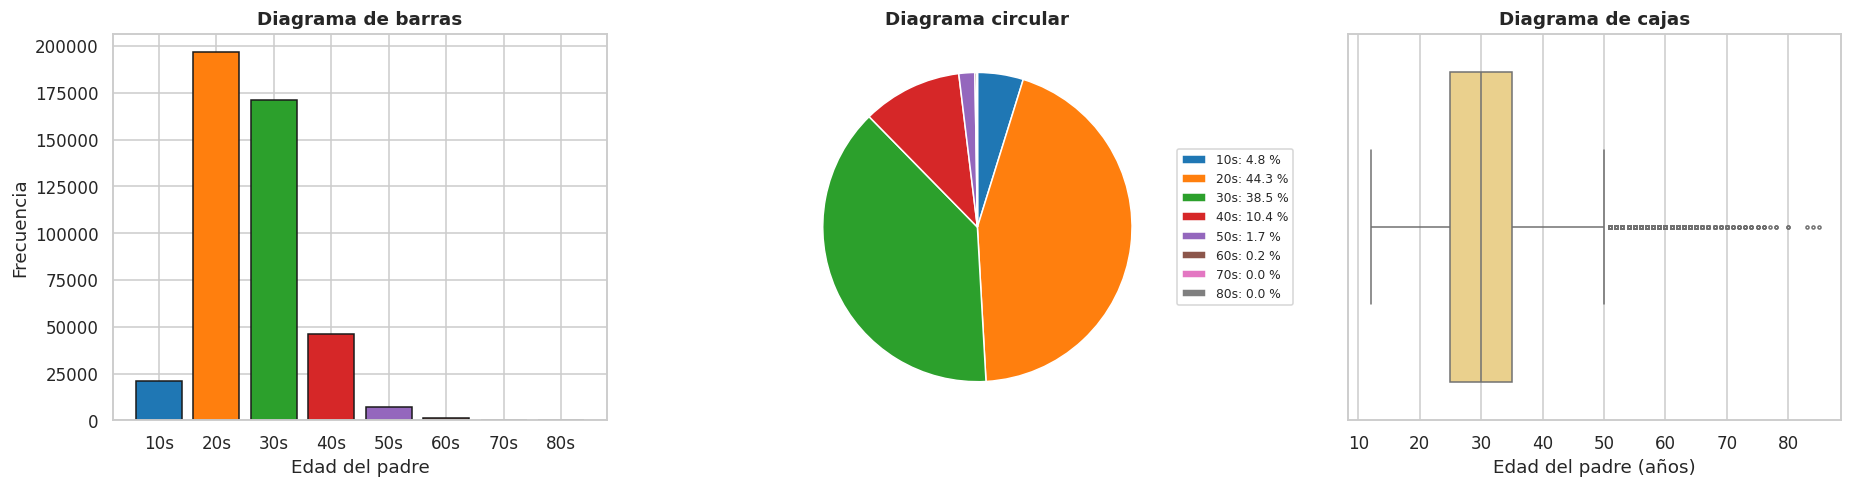

In [13]:
decadas = pd.cut(x, bins=range(10, 100, 10), right=False)
f = decadas.value_counts().sort_index()
etiquetas = [f'{a}s' for a in range(10, 90, 10)]
colores = sns.color_palette('tab10', len(f))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
ax[0].bar(etiquetas, f.values, color=colores, edgecolor='k')
ax[0].set(title='Diagrama de barras', xlabel='Edad del padre', ylabel='Frecuencia')
ax[1].pie(f.values, colors=colores, startangle=90, counterclock=False, wedgeprops=dict(edgecolor='white'))
ax[1].legend([f'{e}: {p:.1f} %' for e, p in zip(etiquetas, f.values / f.sum() * 100)], loc='center left', bbox_to_anchor=(1, .5), fontsize=8)
ax[1].set_title('Diagrama circular')
sns.boxplot(x=x, color='#F9D77E', fliersize=2, ax=ax[2]); ax[2].set(title='Diagrama de cajas', xlabel='Edad del padre (años)')
plt.tight_layout(); plt.savefig('edad_padre_frecuencias.png'); plt.show()

**Interpretación.**
- **Barras y circular** (con las frecuencias por décadas): los padres de 20 a 29 años (44,3 %) y de 30 a 39 años (38,5 %) reúnen más del 80 % de los nacimientos. Los de 10 a 19 años son el 4,8 % y los de 40 a 49 años el 10,4 %. A partir de los 50 años el porcentaje es muy pequeño (1,9 % en total).
- **Diagrama de cajas.** La caja va de 25 a 35 años, con la mediana en 30. Los bigotes llegan hasta los 12 y los 50 años; por encima de 50 hay una larga hilera de puntos aislados (padres mayores), señal de asimetría positiva.

Diagrama de tallos y hojas (muestra aleatoria de 100 padres; tallo = decena, hoja = unidad)

 1 | 889
 2 | 0012222334555555556677777788888899
 3 | 0000000000001111112222233334444455555555566666788899
 4 | 0012235689
 5 | 5


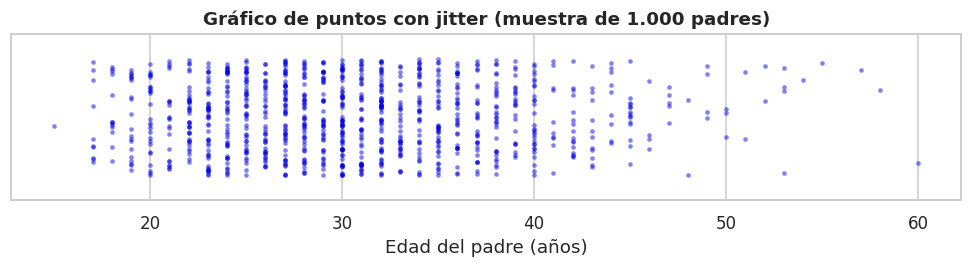

In [14]:
muestra_edad = x.sample(100, random_state=1).values
print("Diagrama de tallos y hojas (muestra aleatoria de 100 padres; tallo = decena, hoja = unidad)\n")
tallos_hojas(muestra_edad)

fig, ax = plt.subplots(figsize=(9, 2.6))
sns.stripplot(x=x.sample(1000, random_state=1), jitter=.35, size=3, alpha=.5, color='blue', ax=ax)
ax.set(title='Gráfico de puntos con jitter (muestra de 1.000 padres)', xlabel='Edad del padre (años)')
plt.tight_layout(); plt.savefig('edad_padre_puntos.png'); plt.show()

**Interpretación.** Con $n=443.777$ no es práctico graficar todos los datos, así que el diagrama de tallos y hojas y el gráfico de puntos se hacen con muestras aleatorias. En el diagrama de tallos y hojas, las filas con más hojas son las de los tallos 2 y 3 (20 a 39 años), y desde ahí cada decena posterior es más corta: la mayoría de los datos está en los veinte y los treinta años, con una cola hacia las edades mayores. El gráfico de puntos (con *jitter* para que no se superpongan) muestra la misma concentración entre 25 y 35 años y algunos puntos sueltos hasta los 60 años o más.

### 3.2 Medidas de posición

In [15]:
pos_edad = tabla_posicion(x)
print("¿Coincide con numpy (método 'weibull', posición p(n+1))?",
      np.allclose(pos_edad['Valor'].values, np.quantile(x, [.25, .5, .75, .2, .4, .6, .8] + [i/10 for i in range(1, 10)] + [.01, .05, .95, .99], method='weibull')))
pos_edad

¿Coincide con numpy (método 'weibull', posición p(n+1))? True


Posición  Valor
Tipo        Medida                      
Cuartiles   Q1               25 %   25.0
            Q2 (mediana)     50 %   30.0
            Q3               75 %   35.0
Quintiles   K1               20 %   24.0
            K2               40 %   28.0
            K3               60 %   32.0
            K4               80 %   37.0
Deciles     D1               10 %   21.0
            D2               20 %   24.0
            D3               30 %   26.0
            D4               40 %   28.0
            D5               50 %   30.0
            D6               60 %   32.0
            D7               70 %   34.0
            D8               80 %   37.0
            D9               90 %   40.0
Percentiles P1                1 %   17.0
            P5                5 %   20.0
            P95              95 %   44.0
            P99              99 %   53.0

**Interpretación.**
- La comprobación con `np.quantile(..., method='weibull')` da `True`, así que nuestra función `cuantiles` reproduce el cálculo de la clase.
- **Cuartiles:** el 25 % de los padres tiene 25 años o menos, el 50 % tiene 30 o menos y el 75 % tiene 35 o menos.
- **Quintiles:** el 20 % tiene hasta 24 años, el 60 % hasta 32 y el 80 % hasta 37.
- **Deciles:** el 10 % tiene 21 años o menos y el 90 % tiene 40 o menos.
- **Percentiles:** el 1 % tiene 17 años o menos y solo el 1 % supera los 53. El 90 % central (de P5 a P95) está entre 20 y 44 años.

### 3.3 Medidas de tendencia central

In [16]:
tc_edad = tabla_central(x)
display(tc_edad.to_frame('EDAD_PADRE').round(3))
print("¿Media geométrica <= media aritmética?", tc_edad['Media geométrica'] <= tc_edad['Media aritmética'])

,EDAD_PADRE
Media aritmética,30.400
Media geométrica,29.467
Mediana,30.000
Moda,30.000
N.º de modas,1.000


¿Media geométrica <= media aritmética? True


**Interpretación.**
- **Media aritmética = 30,40 años:** en promedio, el padre de un recién nacido en Colombia en 2024 tenía 30,4 años.
- **Mediana = 30:** la mitad de los padres tiene 30 años o menos. **Moda = 30**, y es única, lo que confirma una distribución con una sola moda.
- **Media geométrica = 29,47:** cumple $M_g \le \bar{x}$. Para una edad, la media aritmética es la que tiene una interpretación natural; la geométrica la incluimos solo para comparar.
- Media, mediana y moda son casi iguales, con la media un poco por encima de la moda, lo que indica una asimetría positiva leve en el centro de la distribución.

### 3.4 Medidas de dispersión

In [17]:
disp_edad = tabla_dispersion(x)
display(disp_edad.to_frame('EDAD_PADRE').round(4))
print("¿Dm <= S?", disp_edad['Desviación media (Dm)'] <= disp_edad['Desv. estándar muestral (S)'])
display(tabla_cv(x).to_frame('EDAD_PADRE').round(2))

,EDAD_PADRE
Rango,73.0000
RIC (Q3 - Q1),10.0000
Desviación media (Dm),6.0981
Varianza poblacional,59.4251
Varianza muestral (S²),59.4253
Desv. estándar poblacional,7.7088
Desv. estándar muestral (S),7.7088


¿Dm <= S? True


,EDAD_PADRE
CV respecto a la media (%),25.36
CV respecto a la mediana (%),25.73
CV respecto a la moda (%),25.73
CV respecto a la media geométrica (%),26.35


**Interpretación.**
- **Rango = 73 años** (de 12 a 85), pero la mitad central de los datos cabe en solo 10 años (RIC = 10). La variabilidad extrema se debe a pocos casos.
- **Desviación media = 6,10 años:** en promedio, un padre se aleja 6,1 años de la media. Se cumple $D_m \le S_x$.
- **Desviación estándar = 7,71 años:** un padre típico se aleja unos 7,7 años de la media de 30,4. La varianza (59,4 años²) no tiene interpretación directa en las unidades de los datos. Las versiones poblacional y muestral coinciden hasta el cuarto decimal (59,4251 frente a 59,4253), como se espera cuando $n$ es grande, porque $S_x^2 \to \mathrm{Var}(x)$.
- **Coeficiente de variación.** Los cuatro CV están entre 25,4 % y 26,4 %, por debajo del 30 %: la variabilidad es baja y las medidas de tendencia central son representativas. El menor es el de la media (25,36 %), así que la media es la medida central más representativa de `EDAD_PADRE`.

### 3.5 Estandarización y datos atípicos

In [18]:
atip_edad = atipicos(x)
atip_edad.to_frame('EDAD_PADRE').round(3)

,EDAD_PADRE
Intervalo confiable por z: límite inferior,7.273
Intervalo confiable por z: límite superior,53.526
Atípicos por z (|z| > 3),3669.000
% del total,0.827
"Intervalo por cuantiles: límite inferior (Cuantil 0,15 %)",15.000
"Intervalo por cuantiles: límite superior (Cuantil 99,85 %)",62.000
Atípicos por cuantiles,688.000
% del total,0.155
por debajo,168.000
por encima,520.000


**Interpretación.**
- **Criterio de estandarización.** Un dato es confiable si $-3 < z < 3$, es decir, si está en el intervalo $(\bar{x}-3S,\ \bar{x}+3S) = (7{,}3;\ 53{,}5)$. Con este criterio quedan marcados 3.669 padres (0,83 %), todos por encima del límite superior (con $z$ de hasta 7,1). Ninguno queda por debajo: el padre más joven (12 años) tiene $z=-2{,}4$.
- **Criterio bajo no normalidad.** Como la normalidad se rechaza (sección 5), usamos también el intervalo entre los cuantiles 0,15 % y 99,85 %, que es $(15;\ 62)$ y contiene por construcción el 99,7 % de los datos. Quedan por fuera 688 padres (0,16 %): 168 de 14 años o menos y 520 de 63 años o más.
- **Comparación.** El criterio $z$ marca más datos en la cola derecha porque la media y la desviación estándar se ven influidas por esa cola larga. En ambos casos los atípicos son valores posibles (paternidad adolescente o tardía) y no errores evidentes de digitación, por eso los conservamos.

### 3.6 Medidas de forma

In [19]:
forma_edad = tabla_forma(x)
forma_edad.to_frame('EDAD_PADRE').round(4)

,EDAD_PADRE
Momento central 3 (μ3),340.0253
Momento central 4 (μ4),13633.6609
Asimetría de Fisher (μ3/S³),0.7423
Asimetría de Bowley-Yule,0.0000
Asimetría de Pearson ((media-moda)/S),0.0518
Curtosis respecto a la media (μ4/S⁴),3.8608
Curtosis respecto a la mediana ((Q3-Q1)/(P90-P10)),0.5263


**Interpretación.**
- **Asimetría de Fisher = 0,742 > 0:** distribución asimétrica positiva, con cola larga a la derecha, igual que muestran el histograma y el Q-Q plot.
- **Curtosis respecto a la media = 3,86 > 3:** distribución leptocúrtica, es decir, más apuntada que la normal y con colas más pesadas. Con el criterio basado en cuantiles, $CuM = 0{,}526 > 0{,}5$ lleva a la misma conclusión.
- **Bowley-Yule = 0:** los cuartiles son simétricos respecto a la mediana (25, 30 y 35), así que el 50 % central no muestra asimetría. **Pearson = 0,05**, cercano a 0, porque la media (30,4) y la moda (30) casi coinciden. Estos dos coeficientes dependen solo de los cuartiles y de la moda, y por eso no ven la cola; el de Fisher, que usa el tercer momento, sí la recoge. De ahí que la asimetría sea leve en el centro y marcada en la cola derecha.

### Respuesta a la pregunta 1
`EDAD_PADRE` tiene una sola moda, es asimétrica positiva y leptocúrtica. Se centra en los **30 años** (media 30,4; mediana y moda 30) y su variabilidad es baja (S = 7,7; CV = 25,4 %). La mitad de los padres tiene entre 25 y 35 años, el 83 % tiene entre 20 y 39 años y solo el 1,9 % supera los 49. Se aleja de la normal por su cola derecha.

## 4. Pregunta 2: comportamiento de `N_EMB`

### 4.1 Gráficos estadísticos

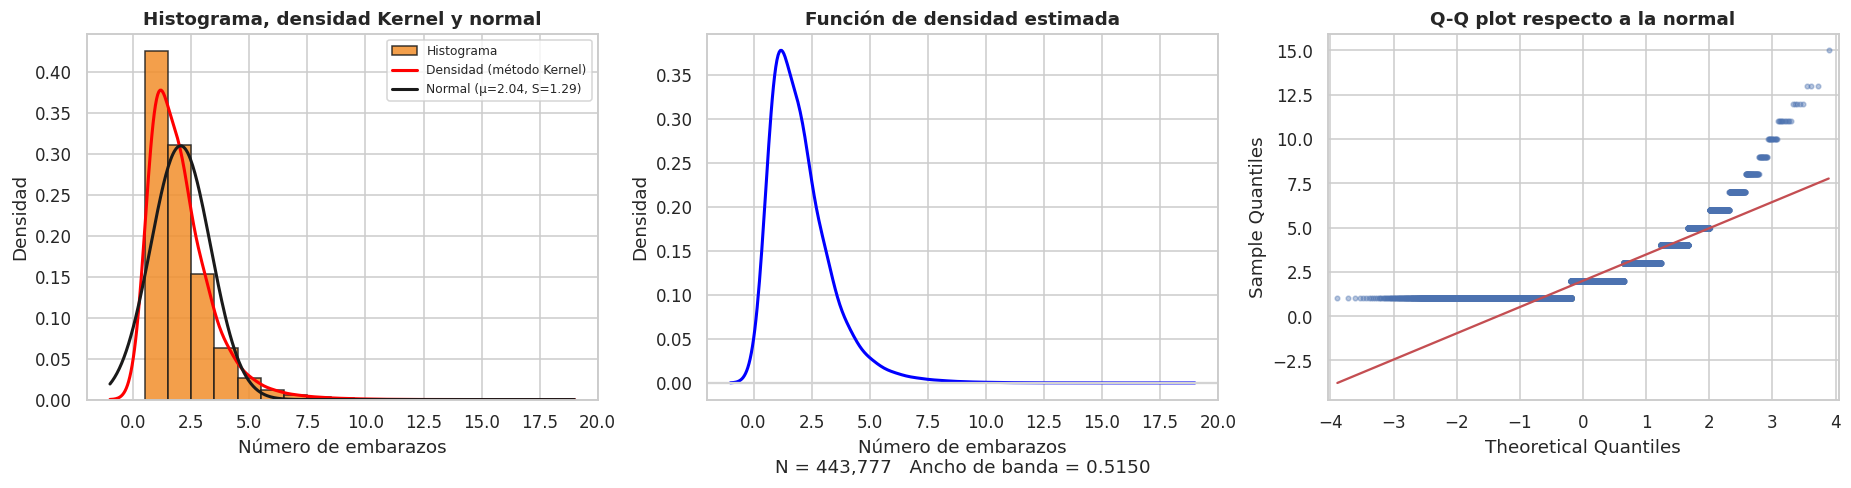

In [20]:
y = df['N_EMB']
bw2 = fig_distribucion(y, 'Número de embarazos', bins=np.arange(.5, y.max() + 1.5, 1), archivo='n_emb_distribucion.png', factor=0.4)

**Interpretación.**
- **Histograma, densidad Kernel y normal.** Como `N_EMB` es discreta, cada barra corresponde a un valor entero. La distribución alcanza su máximo en 1 y baja rápido, con una cola larga hacia la derecha. Con el ancho de banda automático (0,10), la densidad Kernel forma un pico agudo en cada entero, lo que confirma que la variable es discreta. Por eso fijamos un ancho mayor (0,52), que da una curva legible pero que debe leerse solo como tendencia, porque reparte masa en valores menores que 1, que son imposibles. La normal (negra) se ajusta muy mal por la misma razón.
- **Q-Q plot.** Los puntos forman escalones (por ser discreta) y se alejan mucho de la recta: más de la mitad de los datos son 1 o 2 y la cola derecha es mucho más pesada que la de una normal.

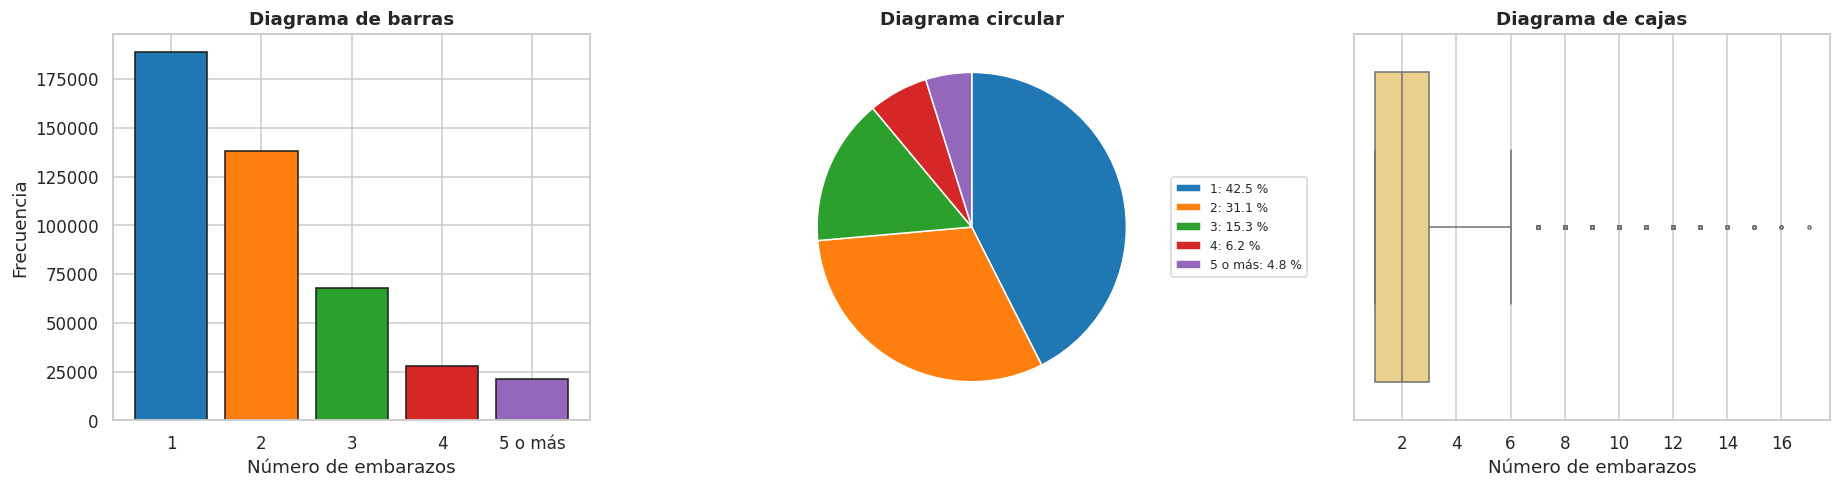

In [21]:
grupo = y.clip(upper=5)
f2 = grupo.value_counts().sort_index()
etiq2 = ['1', '2', '3', '4', '5 o más']
col2 = sns.color_palette('tab10', len(f2))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
ax[0].bar(etiq2, f2.values, color=col2, edgecolor='k')
ax[0].set(title='Diagrama de barras', xlabel='Número de embarazos', ylabel='Frecuencia')
ax[1].pie(f2.values, colors=col2, startangle=90, counterclock=False, wedgeprops=dict(edgecolor='white'))
ax[1].legend([f'{e}: {p:.1f} %' for e, p in zip(etiq2, f2.values / f2.sum() * 100)], loc='center left', bbox_to_anchor=(1, .5), fontsize=8)
ax[1].set_title('Diagrama circular')
sns.boxplot(x=y, color='#F9D77E', fliersize=2, ax=ax[2]); ax[2].set(title='Diagrama de cajas', xlabel='Número de embarazos')
plt.tight_layout(); plt.savefig('n_emb_frecuencias.png'); plt.show()

**Interpretación.**
- **Barras y circular** (con 5 o más embarazos agrupados): el 42,5 % de los nacimientos corresponde a madres en su primer embarazo, el 31,1 % en el segundo, el 15,3 % en el tercero, el 6,2 % en el cuarto y solo el 4,8 % a madres con cinco o más.
- **Diagrama de cajas.** La caja es angosta (de 1 a 3) y la mediana es 2. El bigote superior llega a 6 embarazos y todo lo que lo supera aparece como punto aislado: la cola derecha tiene muchos valores atípicos.

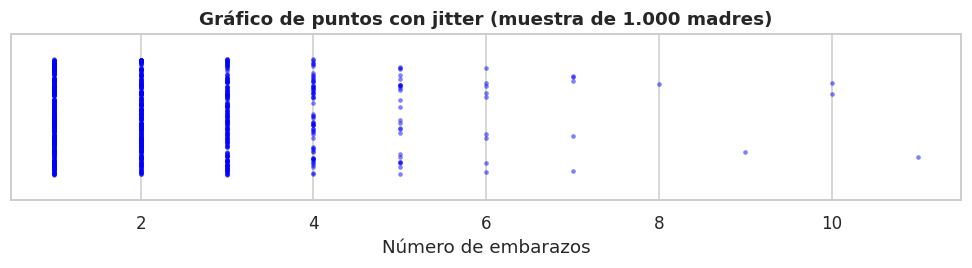

In [22]:
fig, ax = plt.subplots(figsize=(9, 2.6))
sns.stripplot(x=y.sample(1000, random_state=1), jitter=.35, size=3, alpha=.5, color='blue', ax=ax)
ax.set(title='Gráfico de puntos con jitter (muestra de 1.000 madres)', xlabel='Número de embarazos')
plt.tight_layout(); plt.savefig('n_emb_puntos.png'); plt.show()

**Interpretación.** El gráfico de puntos separa los valores enteros en columnas (con ruido vertical para que no se superpongan) y muestra que la mayor concentración está en 1 y 2 embarazos, mientras que los casos de 7 o más son excepcionales. No usamos diagrama de tallos y hojas para esta variable: con tan pocos valores enteros y tan repetidos, el diagrama de barras muestra mejor la información.

### 4.2 Medidas de posición

In [23]:
pos_emb = tabla_posicion(y)
print("¿Coincide con numpy (método 'weibull')?",
      np.allclose(pos_emb['Valor'].values, np.quantile(y, [.25, .5, .75, .2, .4, .6, .8] + [i/10 for i in range(1, 10)] + [.01, .05, .95, .99], method='weibull')))
pos_emb

¿Coincide con numpy (método 'weibull')? True


Posición  Valor
Tipo        Medida                      
Cuartiles   Q1               25 %    1.0
            Q2 (mediana)     50 %    2.0
            Q3               75 %    3.0
Quintiles   K1               20 %    1.0
            K2               40 %    1.0
            K3               60 %    2.0
            K4               80 %    3.0
Deciles     D1               10 %    1.0
            D2               20 %    1.0
            D3               30 %    1.0
            D4               40 %    1.0
            D5               50 %    2.0
            D6               60 %    2.0
            D7               70 %    2.0
            D8               80 %    3.0
            D9               90 %    4.0
Percentiles P1                1 %    1.0
            P5                5 %    1.0
            P95              95 %    4.0
            P99              99 %    7.0

**Interpretación.** Al ser discreta y concentrada en pocos valores, muchos cuantiles se repiten. Como $Q_1$, $K_2$ y $D_4$ valen 1, al menos el 40 % de las madres está en su primer embarazo (el valor real es 42,5 %). La mediana es 2 y el tercer cuartil es 3, es decir, el 75 % de los nacimientos corresponde a madres con tres embarazos o menos. El percentil 95 es 4 y el 99 es 7: aproximadamente el 1 % de las madres tiene 7 embarazos o más.

### 4.3 Medidas de tendencia central

In [24]:
tc_emb = tabla_central(y)
display(tc_emb.to_frame('N_EMB').round(3))
print("¿Media geométrica <= media aritmética?", tc_emb['Media geométrica'] <= tc_emb['Media aritmética'])

,N_EMB
Media aritmética,2.042
Media geométrica,1.742
Mediana,2.000
Moda,1.000
N.º de modas,1.000


¿Media geométrica <= media aritmética? True


**Interpretación.**
- **Moda = 1:** el valor más frecuente es el primer embarazo. **Mediana = 2:** la mitad de las madres tiene dos embarazos o menos.
- **Media aritmética = 2,04:** es el número esperado de embarazos y no tiene por qué ser un entero. La **media geométrica = 1,74** es menor que la aritmética, como debe ser.
- **Moda < mediana < media:** es el orden típico de una distribución asimétrica positiva, en la que la cola derecha jala la media hacia arriba.

### 4.4 Medidas de dispersión

In [25]:
disp_emb = tabla_dispersion(y)
display(disp_emb.to_frame('N_EMB').round(4))
print("¿Dm <= S?", disp_emb['Desviación media (Dm)'] <= disp_emb['Desv. estándar muestral (S)'])
display(tabla_cv(y).to_frame('N_EMB').round(2))

,N_EMB
Rango,16.0000
RIC (Q3 - Q1),2.0000
Desviación media (Dm),0.9120
Varianza poblacional,1.6580
Varianza muestral (S²),1.6580
Desv. estándar poblacional,1.2876
Desv. estándar muestral (S),1.2876


¿Dm <= S? True


,N_EMB
CV respecto a la media (%),63.07
CV respecto a la mediana (%),64.41
CV respecto a la moda (%),165.62
CV respecto a la media geométrica (%),75.90


**Interpretación.**
- **Rango = 16 y RIC = 2:** la mitad central de las madres está entre 1 y 3 embarazos. **Dm = 0,91** y **S = 1,29 embarazos** (se cumple $D_m \le S_x$): en promedio, una madre se aleja unos 1,3 embarazos de la media de 2,04. Otra vez las varianzas poblacional y muestral coinciden.
- **Coeficiente de variación.** Respecto a la media es 63,1 %, una variabilidad moderada (entre 40 % y 80 %), de modo que la media representa al conjunto solo de forma parcial. Aun así es el menor de los cuatro, por lo que es la medida central más representativa. El CV respecto a la moda es 165,6 %: aunque 1 es el valor más frecuente, los demás datos se alejan mucho de él en promedio, lo que lo hace poco representativo.

### 4.5 Estandarización y datos atípicos

In [26]:
atip_emb = atipicos(y)
atip_emb.to_frame('N_EMB').round(3)

,N_EMB
Intervalo confiable por z: límite inferior,-1.821
Intervalo confiable por z: límite superior,5.904
Atípicos por z (|z| > 3),9901.000
% del total,2.231
"Intervalo por cuantiles: límite inferior (Cuantil 0,15 %)",1.000
"Intervalo por cuantiles: límite superior (Cuantil 99,85 %)",9.000
Atípicos por cuantiles,616.000
% del total,0.139
por debajo,0.000
por encima,616.000


**Interpretación.**
- **Criterio $z$.** El intervalo confiable $(\bar{x}-3S,\ \bar{x}+3S)$ es $(-1{,}8;\ 5{,}9)$, así que resultan atípicas las madres con 6 o más embarazos: 9.901 casos (2,23 %). El límite inferior es negativo, algo sin sentido para un conteo, una señal más de que la normalidad no es un buen modelo.
- **Criterio por cuantiles (0,15 % y 99,85 %).** El intervalo es $(1;\ 9)$, y solo son atípicos los 616 casos (0,14 %) con más de 9 embarazos. Es el criterio más apropiado aquí porque no depende de la normalidad.
- Las dos reglas difieren porque la desviación estándar es muy sensible a la cola derecha. Los valores marcados son altos pero posibles, y los conservamos (sección 2).

### 4.6 Medidas de forma

In [27]:
forma_emb = tabla_forma(y)
forma_emb.to_frame('N_EMB').round(4)

,N_EMB
Momento central 3 (μ3),4.2624
Momento central 4 (μ4),26.4047
Asimetría de Fisher (μ3/S³),1.9966
Asimetría de Bowley-Yule,0.0000
Asimetría de Pearson ((media-moda)/S),0.8089
Curtosis respecto a la media (μ4/S⁴),9.6058
Curtosis respecto a la mediana ((Q3-Q1)/(P90-P10)),0.6667


**Interpretación.**
- **Asimetría de Fisher = 2,00:** asimetría positiva fuerte. El coeficiente de Pearson ($\approx 0{,}81$; la media supera a la moda en 1,04) lo confirma. **Bowley-Yule = 0** porque los cuartiles (1, 2 y 3) son simétricos respecto a la mediana; como antes, este coeficiente no ve la cola, que sí capta el tercer momento.
- **Curtosis respecto a la media = 9,61 > 3** y **$CuM = 0{,}667 > 0{,}5$:** distribución leptocúrtica, con alta concentración en 1 y 2 y colas muy pesadas. El 9,6 es mucho mayor que el 3,9 de `EDAD_PADRE`.

### Respuesta a la pregunta 2
`N_EMB` es una variable discreta con moda en 1 (42,5 %), mediana 2 y media 2,04. Tiene asimetría positiva fuerte (2,00), es leptocúrtica (9,6) y su variabilidad es moderada (CV = 63 %). El 73,6 % de los nacimientos corresponde a madres con uno o dos embarazos, y alrededor del 1 % tiene 7 o más. Se aleja claramente de la normal.

## 5. Supuesto de normalidad (Shapiro-Wilk)

Para cada variable contrastamos

$H_0$: la variable proviene de una distribución normal  vs.  $H_1$: la variable no proviene de una distribución normal,

con $\alpha = 0{,}05$.

**Detalle metodológico.** `scipy.stats.shapiro` solo es confiable hasta unos 5.000 datos (SciPy lo advierte, y el algoritmo de Royston, 1995, llega hasta ese tamaño), y aquí $n = 443.777$. Por eso aplicamos Shapiro-Wilk a una **muestra aleatoria de 5.000 registros** (con semilla fija) y lo complementamos con dos pruebas más adecuadas para $n$ grande, aplicadas a toda la base: la de **D'Agostino-Pearson** (basada en asimetría y curtosis) y la de **Anderson-Darling**. En las comparaciones de potencia entre pruebas de normalidad, Shapiro-Wilk resulta la más potente y Anderson-Darling la sigue de cerca, sobre todo con distribuciones asimétricas como las nuestras (Razali y Wah, 2011; Yap y Sim, 2011). El Q-Q plot de las secciones 3.1 y 4.1 completa el diagnóstico.

In [28]:
muestra = df.sample(5000, random_state=1)
filas = []
for c in df.columns:
    W, p_sw = stats.shapiro(muestra[c])
    K2, p_k2 = stats.normaltest(df[c])
    ad = stats.anderson(df[c], dist='norm')
    filas.append([c, W, p_sw, K2, p_k2, ad.statistic, ad.critical_values[-1]])

norm = pd.DataFrame(filas, columns=['Variable', 'W (Shapiro, n=5000)', 'p Shapiro', "K² (D'Agostino)", "p D'Agostino",
                                    'A² (Anderson-Darling)', 'A² crítico 1 %']).set_index('Variable')
norm.style.format({'W (Shapiro, n=5000)': '{:.4f}', 'p Shapiro': '{:.2e}', "K² (D'Agostino)": '{:,.0f}',
                   "p D'Agostino": '{:.2e}', 'A² (Anderson-Darling)': '{:,.0f}', 'A² crítico 1 %': '{:.3f}'})

,"W (Shapiro, n=5000)",p Shapiro,K² (D'Agostino),p D'Agostino,A² (Anderson-Darling),A² crítico 1 %
Variable,,,,,,
EDAD_PADRE,0.9703,5.45e-31,"39,727",0.00e+00,"2,759",1.092
N_EMB,0.7635,8.50e-65,"189,954",0.00e+00,"31,414",1.092


**Interpretación.** Con las tres pruebas el p-valor es prácticamente 0 ($<0{,}05$) y el estadístico de Anderson-Darling supera por mucho su valor crítico, así que **rechazamos $H_0$: ninguna de las dos variables es normal.**
- `EDAD_PADRE`: W = 0,970, relativamente cerca de 1 (una desviación moderada, debida a la cola derecha).
- `N_EMB`: W = 0,764, mucho más lejos de 1; la desviación es grande, como anticipaban su asimetría (2,0), su curtosis (9,6) y su Q-Q plot.

Con un $n$ tan grande, cualquier desviación diminuta se rechaza, por lo que el p-valor informa poco por sí solo; son los gráficos y las medidas de forma los que muestran cuánto se aleja cada variable de la normal. Por eso preferimos las medidas robustas (mediana, RIC y cuantiles) y, para la correlación, los coeficientes por rangos (Spearman y Kendall).

## 6. Pregunta 3: relación entre `EDAD_PADRE` y `N_EMB`

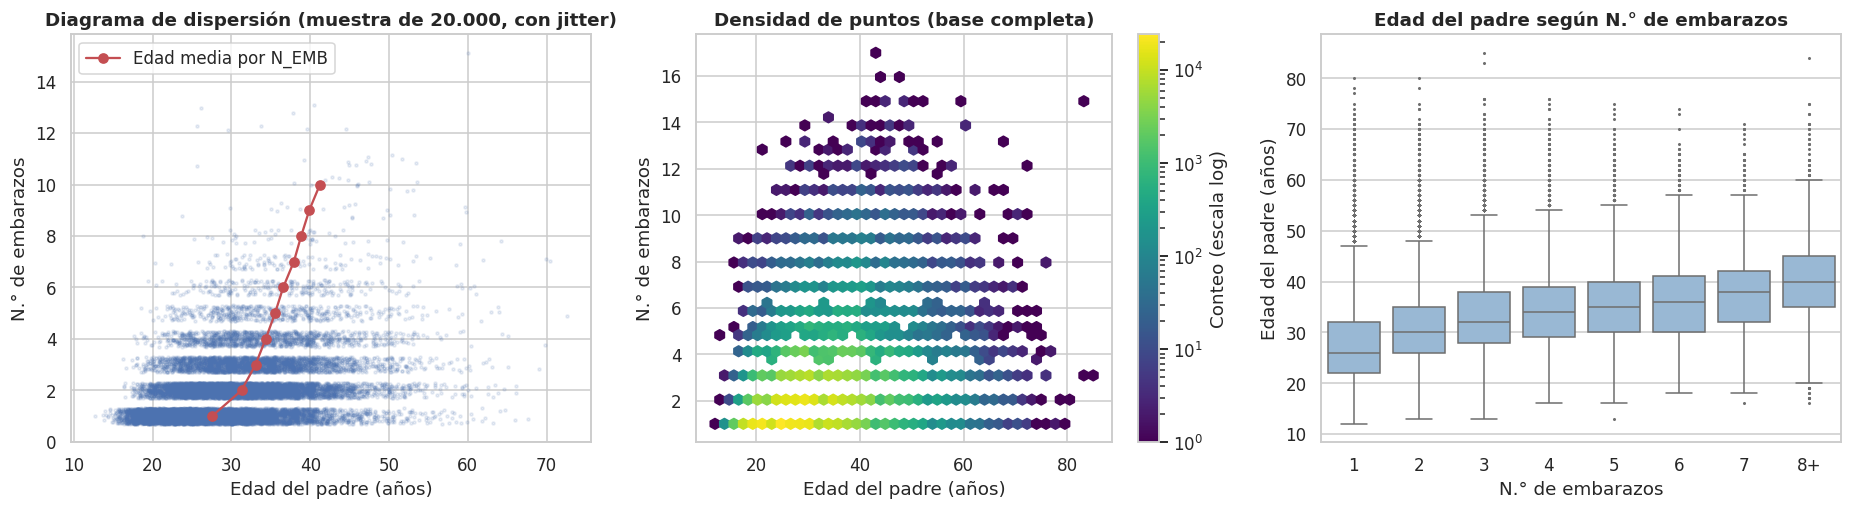

In [29]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
rng = np.random.default_rng(1)
m = df.sample(20000, random_state=1)

# (a) Dispersión con ruido (jitter), porque N_EMB es discreta
ax[0].scatter(m['EDAD_PADRE'] + rng.uniform(-.5, .5, len(m)), m['N_EMB'] + rng.uniform(-.3, .3, len(m)), s=4, alpha=.12, color='#4C72B0')
medias = df[df['N_EMB'] <= 10].groupby('N_EMB')['EDAD_PADRE'].mean()
ax[0].plot(medias.values, medias.index, 'o-', color='#C44E52', label='Edad media por N_EMB'); ax[0].legend()
ax[0].set(title='Diagrama de dispersión (muestra de 20.000, con jitter)', xlabel='Edad del padre (años)', ylabel='N.° de embarazos')

# (b) Densidad de puntos con la base completa
hb = ax[1].hexbin(df['EDAD_PADRE'], df['N_EMB'], gridsize=40, cmap='viridis', mincnt=1, bins='log')
plt.colorbar(hb, ax=ax[1], label='Conteo (escala log)')
ax[1].set(title='Densidad de puntos (base completa)', xlabel='Edad del padre (años)', ylabel='N.° de embarazos')

# (c) Comparación de la variabilidad con diagramas de cajas
g = df.assign(N_EMB_g=df['N_EMB'].clip(upper=8).map(lambda v: '8+' if v == 8 else str(v)))
sns.boxplot(data=g, x='N_EMB_g', y='EDAD_PADRE', order=[str(i) for i in range(1, 8)] + ['8+'], color='#8FB8DE', fliersize=1, ax=ax[2])
ax[2].set(title='Edad del padre según N.° de embarazos', xlabel='N.° de embarazos', ylabel='Edad del padre (años)')
plt.tight_layout(); plt.savefig('dispersion.png'); plt.show()

**Interpretación.** Como `N_EMB` es discreta, la nube de puntos forma filas horizontales; por eso añadimos un poco de ruido (*jitter*) y la complementamos con un gráfico de densidad hecho con toda la base. Se observa una **tendencia positiva**: a más embarazos, mayor edad promedio del padre (línea roja). Los diagramas de cajas lo confirman: la mediana de la edad del padre sube de unos 26 años con un embarazo a unos 40 con ocho o más. Las cajas se solapan bastante, así que la relación es creciente pero con mucha dispersión. Además es aproximadamente monótona, lo que hace apropiados los coeficientes por rangos.

In [30]:
n = len(df)
r,   p_r = stats.pearsonr(df['EDAD_PADRE'], df['N_EMB'])
rho, p_s = stats.spearmanr(df['EDAD_PADRE'], df['N_EMB'])
tau, p_k = stats.kendalltau(df['EDAD_PADRE'], df['N_EMB'])      # tau-b: corrige los empates

z = np.arctanh(r); ee = 1 / np.sqrt(n - 3)
ic_r = np.tanh([z - 1.96 * ee, z + 1.96 * ee])

fmt_p = lambda p: '≈ 0 (< 1e-300)' if p == 0 else f'{p:.2e}'
corr = pd.DataFrame({'Coeficiente': [r, rho, tau], 'p-valor': [fmt_p(p_r), fmt_p(p_s), fmt_p(p_k)],
                     'Supone': ['Relación lineal (y normalidad para inferencia)', 'Relación monótona (usa rangos)', 'Relación monótona (pares concordantes)']},
                    index=['Pearson (r)', 'Spearman (ρ)', 'Kendall (τ-b)'])
display(corr.style.format({'Coeficiente': '{:.4f}'}))
print(f"IC 95 % de Pearson (transformación de Fisher): [{ic_r[0]:.4f}, {ic_r[1]:.4f}]")
print(f"r² = {r**2:.3f}  ->  la relación lineal explica ~{r**2*100:.1f} % de la variabilidad compartida")

,Coeficiente,p-valor,Supone
Pearson (r),0.3400,≈ 0 (< 1e-300),Relación lineal (y normalidad para inferencia)
Spearman (ρ),0.3672,≈ 0 (< 1e-300),Relación monótona (usa rangos)
Kendall (τ-b),0.2872,≈ 0 (< 1e-300),Relación monótona (pares concordantes)


IC 95 % de Pearson (transformación de Fisher): [0.3374, 0.3426]
r² = 0.116  ->  la relación lineal explica ~11.6 % de la variabilidad compartida


**Interpretación.**
- **Pearson $r = 0{,}340$** (IC 95 %: 0,337 a 0,343): correlación lineal positiva, de intensidad débil a moderada (ver la escala más abajo). Con $r^2 = 0{,}116$, la edad del padre se asocia linealmente con solo el 12 % de la variabilidad de `N_EMB`.
- **Spearman $\rho = 0{,}367$:** un poco mayor que Pearson, lo que sugiere una relación más monótona que lineal. La fuerte asimetría de `N_EMB` y sus valores extremos pueden estar bajando a Pearson.
- **Kendall $\tau_b = 0{,}287$:** es menor que los otros dos, y es normal, porque $\tau$ mide la diferencia entre la probabilidad de pares concordantes y discordantes, en una escala distinta a la de $\rho$. Usamos $\tau_b$, que corrige los muchos empates de `N_EMB`.
- Los p-valores son prácticamente 0 en los tres casos, pero con $n \approx 4{,}4\times10^5$ cualquier correlación distinta de cero sale significativa. Lo informativo es el tamaño del efecto, y su etiqueta depende de la escala que se use: según Evans (1996), valores entre 0,20 y 0,39 indican una correlación **débil** y entre 0,40 y 0,59, moderada, mientras que según Cohen (1988) desde 0,30 ya es moderada. Pearson y Spearman (0,34 y 0,37) quedan justo en esa frontera, así que lo más honesto es reportar los valores y describir la relación como positiva, de intensidad **débil a moderada**.
- Como las variables no son normales (sección 5), la inferencia de Pearson debe tomarse con cautela y damos más peso a Spearman y Kendall.

In [31]:
# Sensibilidad: ¿cambian los coeficientes si se excluyen los datos atípicos?
def coefs(d):
    return [len(d), stats.pearsonr(d['EDAD_PADRE'], d['N_EMB'])[0],
            stats.spearmanr(d['EDAD_PADRE'], d['N_EMB'])[0], stats.kendalltau(d['EDAD_PADRE'], d['N_EMB'])[0]]

lim = {c: cuantiles(df[c], [.0015, .9985]) for c in df}
ok_cuant = np.logical_and.reduce([(df[c] >= lim[c][0]) & (df[c] <= lim[c][1]) for c in df])
zs = (df - df.mean()) / df.std()
ok_z = (zs.abs() <= 3).all(axis=1)

sens = pd.DataFrame([coefs(df), coefs(df[ok_cuant]), coefs(df[ok_z])],
                    columns=['n', 'Pearson', 'Spearman', 'Kendall'],
                    index=['Base completa', 'Sin atípicos (cuantiles 0,15 % y 99,85 %)', 'Sin atípicos (|z| > 3)'])
sens.round(4)

,n,Pearson,Spearman,Kendall
Base completa,443777,0.3400,0.3672,0.2872
"Sin atípicos (cuantiles 0,15 % y 99,85 %)",442485,0.3384,0.3648,0.2853
Sin atípicos (|z| > 3),430587,0.3273,0.3496,0.2741


**Interpretación.** Al excluir los atípicos por el criterio de cuantiles (1.292 registros, 0,29 %), los coeficientes casi no cambian (Pearson 0,338; Spearman 0,365; Kendall 0,285). Con el criterio $|z|>3$, que elimina más datos (13.190, el 3,0 %), bajan un poco (0,327; 0,350; 0,274), pero la conclusión es la misma. La correlación no depende de los valores extremos, lo que justifica haberlos conservado.

### Control por la edad de la madre

Es razonable pensar que la edad de la madre influye en las dos variables: las madres mayores han tenido más tiempo para acumular embarazos y tienden a tener parejas mayores. Si es así, buena parte de la correlación anterior sería indirecta. Lo comprobamos de dos maneras: con la **correlación parcial de Spearman** (la correlación entre `EDAD_PADRE` y `N_EMB` una vez descontado el efecto de `EDAD_MADRE`) y calculando la correlación dentro de cada grupo de edad de la madre.

In [32]:
# La edad de la madre viene en grupos quinquenales (1 = 10-14, 2 = 15-19, ..., 8 = 45-49, 9 = 50-54; 99 = sin información)
ext = tabla[['EDAD_PADRE', 'N_EMB', 'EDAD_MADRE']].reset_index(drop=True)
ext = ext[(ext['EDAD_PADRE'] != 999) & (ext['N_EMB'] != 99) & (ext['EDAD_MADRE'] != 99)]
print(f"Registros: {len(ext):,} (¿los mismos de la base limpia? {len(ext) == len(df)})\n")

# Correlación de Spearman entre cada par y correlación parcial controlando por EDAD_MADRE
R = ext.rank().corr()
r_xy, r_xz, r_yz = R.loc['EDAD_PADRE', 'N_EMB'], R.loc['EDAD_PADRE', 'EDAD_MADRE'], R.loc['N_EMB', 'EDAD_MADRE']
parcial = (r_xy - r_xz * r_yz) / np.sqrt((1 - r_xz ** 2) * (1 - r_yz ** 2))
print(f"Spearman EDAD_PADRE - N_EMB:        {r_xy:.3f}")
print(f"Spearman EDAD_PADRE - EDAD_MADRE:   {r_xz:.3f}")
print(f"Spearman N_EMB - EDAD_MADRE:        {r_yz:.3f}")
print(f"Spearman parcial (controlando EDAD_MADRE): {parcial:.3f}\n")

# Correlación dentro de cada grupo de edad de la madre (se omiten grupos con menos de 500 registros)
nombres = {1: '10-14', 2: '15-19', 3: '20-24', 4: '25-29', 5: '30-34', 6: '35-39', 7: '40-44', 8: '45-49'}
filas = []
for g, d in ext.groupby('EDAD_MADRE'):
    if len(d) >= 500:
        filas.append([nombres[g], len(d), stats.pearsonr(d['EDAD_PADRE'], d['N_EMB'])[0],
                      stats.spearmanr(d['EDAD_PADRE'], d['N_EMB'])[0], stats.kendalltau(d['EDAD_PADRE'], d['N_EMB'])[0]])
por_grupo = pd.DataFrame(filas, columns=['Edad de la madre', 'n', 'Pearson', 'Spearman', 'Kendall']).set_index('Edad de la madre')
print(por_grupo.round(3).to_string())

Registros: 443,777 (¿los mismos de la base limpia? True)

Spearman EDAD_PADRE - N_EMB:        0.367
Spearman EDAD_PADRE - EDAD_MADRE:   0.660
Spearman N_EMB - EDAD_MADRE:        0.456
Spearman parcial (controlando EDAD_MADRE): 0.099

                       n  Pearson  Spearman  Kendall
Edad de la madre                                    
10-14               3131    0.037     0.043    0.037
15-19              63351    0.155     0.185    0.155
20-24             118033    0.143     0.154    0.124
25-29             116425    0.097     0.096    0.075
30-34              86250    0.067     0.067    0.052
35-39              43990    0.056     0.052    0.039
40-44              11818    0.061     0.054    0.039
45-49                739    0.091     0.087    0.061


**Interpretación.**
- La edad de la madre está muy relacionada con la del padre ($\rho = 0{,}66$) y bastante con el número de embarazos ($\rho = 0{,}46$), tal como se esperaba.
- Al descontar su efecto, la correlación parcial entre `EDAD_PADRE` y `N_EMB` cae de 0,367 a **0,099**: casi desaparece.
- Dentro de cada grupo de edad de la madre la correlación es muy débil (Spearman entre 0,04 y 0,19), y es algo mayor en las madres de 15 a 24 años (entre 0,15 y 0,19).
- **Limitación.** La edad de la madre solo está en grupos de cinco años, así que el control es aproximado: dentro de cada grupo todavía queda variación de edad que no estamos descontando. Aun así, el resultado indica que la mayor parte de la correlación original refleja que los padres y las madres mayores van juntos, y no un vínculo directo entre la edad del padre y el número de embarazos.

### Respuesta a la pregunta 3
Sí, `EDAD_PADRE` y `N_EMB` están correlacionadas de forma positiva y con intensidad **débil a moderada** (Pearson 0,34; Spearman 0,37; Kendall 0,29; débil según Evans, 1996, y moderada según Cohen, 1988). Los tres coeficientes coinciden en signo y en orden de magnitud, lo que da solidez al resultado, y no cambian al excluir los datos atípicos. Sin embargo, esa correlación es en gran parte **indirecta**: al controlar por la edad de la madre, la correlación parcial de Spearman baja a 0,10. Recordemos, además, que correlación no implica causalidad.

## 7. Conclusiones

1. **Edad del padre.** Se concentra alrededor de los 30 años, con asimetría positiva y cola derecha, baja variabilidad (CV = 25,4 %) y sin normalidad. Cuatro de cada cinco padres tienen entre 20 y 39 años.
2. **Número de embarazos.** Es una variable discreta en la que predominan las madres en su primer o segundo embarazo (73,6 %), con fuerte asimetría y muy lejos de la normal.
3. **Relación entre ambas.** La correlación es positiva y de intensidad débil a moderada (r = 0,34; ρ = 0,37; τ = 0,29) y estable al excluir atípicos. Pero buena parte se explica por la edad de la madre: al controlarla, la correlación parcial de Spearman baja a 0,10. En el contexto de los datos, los padres mayores aparecen junto a madres con más embarazos (la edad media del padre va de unos 27,5 años en el primer embarazo a unos 38,8 en el octavo) sobre todo porque las parejas mayores han tenido más tiempo para acumular embarazos.
4. **Calidad de los datos.** El 2,2 % de los registros tenía códigos de “sin información” (999 y 99) que, sin tratar, distorsionan las medidas: la edad media del padre saldría en 52 años en lugar de 30. Esos faltantes se concentran en certificados incompletos, y la edad se declara con un redondeo moderado (índice de Whipple = 122). Revisar el diccionario de datos antes de calcular estadísticos es indispensable.
5. **Medidas robustas.** Como no hay normalidad, la mediana, el RIC, los cuantiles y los coeficientes por rangos son más fiables que la media, la desviación estándar y Pearson. Además, los coeficientes de asimetría basados en cuartiles (Bowley-Yule) o en la moda (Pearson) no detectan la cola derecha, que sí capta el de Fisher.

### Limitaciones
- Eliminamos los registros incompletos; si la ausencia del dato del padre no es aleatoria (y vimos que se concentra en ciertos certificados), puede haber sesgo, aunque la pérdida es de solo 2,2 %.
- Con esta base no se pueden verificar los errores de diligenciamiento del certificado.
- `N_EMB` es un dato de la madre, así que su relación con la edad del padre es indirecta.
- La edad de la madre solo está en grupos quinquenales, por lo que el control por esa variable es aproximado.
- Con un $n$ tan grande, las pruebas de hipótesis rechazan casi cualquier hipótesis nula; por eso priorizamos el tamaño del efecto y los gráficos.

## Referencias
- Cohen, J. (1988). *Statistical power analysis for the behavioral sciences* (2.ª ed.). Routledge.
- DANE. *Estadísticas Vitales (EEVV): Nacimientos 2024*. Microdatos, catálogo 878. https://microdatos.dane.gov.co/index.php/catalog/878
- D'Agostino, R. B. (1971). An omnibus test of normality for moderate and large sample size. *Biometrika*, 58, 341-348.
- D'Agostino, R. y Pearson, E. S. (1973). Tests for departure from normality. *Biometrika*, 60, 613-622.
- Dong, Y. y Peng, C.-Y. J. (2013). Principled missing data methods for researchers. *SpringerPlus*, 2, 222. https://doi.org/10.1186/2193-1801-2-222
- Evans, J. D. (1996). *Straightforward statistics for the behavioral sciences*. Brooks/Cole.
- Kendall, M. G. (1938). A new measure of rank correlation. *Biometrika*, 30(1-2), 81-93.
- Kendall, M. G. (1945). The treatment of ties in ranking problems. *Biometrika*, 33(3), 239-251. https://doi.org/10.1093/biomet/33.3.239
- Little, R. J. A. y Rubin, D. B. (2019). *Statistical analysis with missing data* (3.ª ed.). Wiley.
- Naciones Unidas, División de Estadística. *Demographic Yearbook: Whipple's Index* (notas de la Tabla 1c). https://unstats.un.org/unsd/Demographic/products/dyb/DYBcensus/V1_Notes1c.pdf
- Razali, N. M. y Wah, Y. B. (2011). Power comparisons of Shapiro-Wilk, Kolmogorov-Smirnov, Lilliefors and Anderson-Darling tests. *Journal of Statistical Modeling and Analytics*, 2(1), 21-33.
- Ríos-Gutiérrez, A. *Estadística descriptiva para datos univariados* (diapositivas del curso). Universidad Industrial de Santander.
- Royston, P. (1995). Remark AS R94: A remark on Algorithm AS 181: The W-test for normality. *Applied Statistics*, 44(4), 547-551. https://doi.org/10.2307/2986146
- Schafer, J. L. (1999). Multiple imputation: a primer. *Statistical Methods in Medical Research*, 8(1), 3-15. https://doi.org/10.1177/096228029900800102
- Schafer, J. L. y Graham, J. W. (2002). Missing data: our view of the state of the art. *Psychological Methods*, 7(2), 147-177. https://doi.org/10.1037/1082-989X.7.2.147
- Shapiro, S. S. y Wilk, M. B. (1965). An analysis of variance test for normality (complete samples). *Biometrika*, 52(3-4), 591-611.
- Shryock, H. S., Siegel, J. S. y colaboradores (1976). *The methods and materials of demography* (ed. condensada). Academic Press.
- Spearman, C. (1904). The proof and measurement of association between two things. *American Journal of Psychology*, 15(1), 72-101.
- Virtanen, P. et al. (2020). SciPy 1.0: fundamental algorithms for scientific computing in Python. *Nature Methods*, 17, 261-272. https://doi.org/10.1038/s41592-019-0686-2
- Yap, B. W. y Sim, C. H. (2011). Comparisons of various types of normality tests. *Journal of Statistical Computation and Simulation*, 81(12), 2141-2155. https://doi.org/10.1080/00949655.2010.520163

## Anexo: código
El código completo está en las celdas de este cuaderno y también en el archivo `Tarea2_codigo.py`, exportado directamente de él.